In [1]:
import numpy as np
import matplotlib.pyplot as plt
from hcipy import *

import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.path.dirname('adc_sims'), '..')))
from slicing_class import adcFitter2

In [ ]:
fieldcube = read_field('/Users/Katie/Documents/MagAO-X/simulations/adc_sims/lab_analysis/fields/unsats/7725_05offset.fits')

844

In [3]:
def moving_average(a, n=10):
    ret = np.cumsum(a, dtype=float)
    ret[n:] = ret[n:] - ret[:-n]
    return ret[n - 1:] / n

def reject_outliers(data):
    std = np.nanstd(data)
    mean = np.nanmean(data)
    indices = np.where((data < mean+1*std) & (data > mean-1*std)) #the indicies of numbers we're NOT rejecting
    return data[indices]

def block_means(vector, block_size=50):
    vector = np.asarray(vector)
    n_blocks = int(np.ceil(len(vector) / block_size))
    means = [vector[i*block_size:(i+1)*block_size].mean() for i in range(n_blocks)]
    return np.array(means)

In [4]:
#system params
wavelength = 764E-9
bw = 120E-9
grating_angle = 28
grating_freq = 47

ADC = adcFitter2(wavelength=wavelength,bandwidth=bw,grating_angle=grating_angle,grating_freq=grating_freq,snr_threshold=2.3,speckle_window=60)

In [5]:
def est_center(img,extent=40):

    cois = np.zeros((4,2))

    for i in range(4):
        speckle_number = i

        speckle_coords = np.array([[0, ADC.grating_freq * ADC.normalized_wavelength],[ADC.grating_freq * ADC.normalized_wavelength,0],[0, -ADC.grating_freq * ADC.normalized_wavelength],[-ADC.grating_freq * ADC.normalized_wavelength,0]])
        speckle_center = speckle_coords[speckle_number]
        rect = make_rotated_aperture(make_rectangular_aperture(size=(extent,extent), center=speckle_center), np.deg2rad(-ADC.grating_angle))(img.grid)

        speckle_img = rect * img

        #find the center of intensity of the speckle area and window the ORIGINAL image around that center
        center_of_intensity = np.array([sum(speckle_img*speckle_img.grid.x)/sum(speckle_img),sum(speckle_img*speckle_img.grid.y)/sum(speckle_img)])
        window_size=ADC.speckle_window
        new_img = ADC.window_field(img,[center_of_intensity[0],center_of_intensity[1]],window_size,window_size)

        coi = np.array([sum(new_img*new_img.grid.x)/sum(new_img),sum(new_img*new_img.grid.y)/sum(new_img)])

        cois[i,:] = center_of_intensity + coi

    print(cois)
    overall_coi = np.mean(cois,axis=0)
    return overall_coi

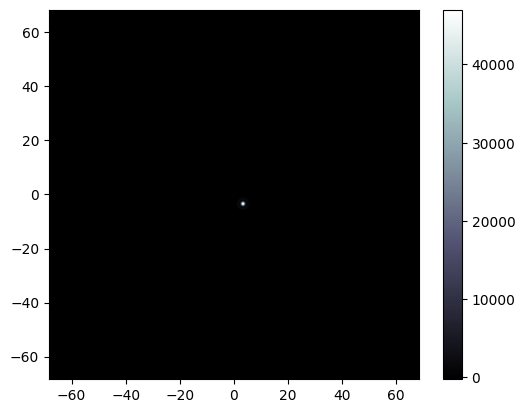

In [6]:
img = fieldcube[2]
img = img - np.median(img)
img[img < 0] = 0
hp = ADC.hpf(img,30)

imshow_field(hp,cmap='bone')
plt.colorbar()

In [7]:
img = fieldcube[2]
img = ADC.crop_image(img,extent=510,mask_diam=40)
img = img - np.median(img)
img[img < 0] = 0
hp = ADC.hpf(img,20)
#img = ADC.crop_image(img,extent=512,mask_diam=20)

# c = est_center(hp,extent=30)
# print(f'center: {c}')
c = np.array([0,0])

s = ADC.all_speckle_angles(hp)
dx, dy = ADC.speckles_dxdy(hp,filtered=True,center = c)

imshow_field(img)
plt.title('filtered')
plt.colorbar()
plt.scatter(dx,dy,color='orange',label='est radiation center')
plt.scatter(c[0],c[1],color='red',label='est psf center')
plt.scatter(0,0,color='green',label='(0,0)')
plt.legend()

print(f'speckle angles {s}')
print(f'dy: {dy}')
print(f'dx: {dx}')
print(f'est magnitude: {np.sqrt(dx**2 + dy**2)}')
print(f'est dir: {np.degrees(np.atan2(dy,dx))}')


ValueError: operands could not be broadcast together with shapes (260100,) (0,) 

In [46]:
disps = np.zeros(len(fieldcube))
commands = []
speckle_angles = []
mags = []
angs = []
c = np.array([0,0])

for i, field in enumerate(fieldcube):
    img = ADC.crop_image(field,extent=510,mask_diam=40)
    img = img - np.median(img)
    img[img < 0] = 0
    hp = ADC.hpf(img,20)

    c = est_center(hp,extent=30)
    print(f'center: {c}')

    s = ADC.all_speckle_angles(hp)
    est_x, est_y = ADC.speckles_dxdy(hp,filtered=True,center = c)
    sq = np.sqrt(est_x**2+est_y**2)
    ang = np.degrees(np.arctan2(est_y,est_x))
    speckle_angles.append(s)
    mags.append(sq)
    angs.append(ang)

[[ 12.93850629  68.86819345]
 [ 36.67962228  -1.30385939]
 [-16.28327134 -61.14785748]
 [-45.12004507  12.57342012]]
center: [-2.94629696  4.74747418]
[[ 101.19744105  -58.7542609 ]
 [  12.38995339    4.75523391]
 [ 293.74865829 -392.80119132]
 [ -33.93471525    4.78049116]]
center: [  93.35033437 -110.50493179]
[[ 36.29891308  37.3380565 ]
 [ 50.53745576 -15.80900684]
 [-40.63951892 -43.78871746]
 [-63.08353176  -9.71473354]]
center: [-4.22167046 -7.99360033]


ValueError: operands could not be broadcast together with shapes (0,) (2500,) 

In [ ]:
mags = np.array(mags)
angs = np.array(angs)
speckle_angles = np.array(speckle_angles)
angle_avgs = np.nanmean(speckle_angles,axis=0)
print(angle_avgs)

[ 10.38449619 -20.72373358  16.13037879 -27.24005639]


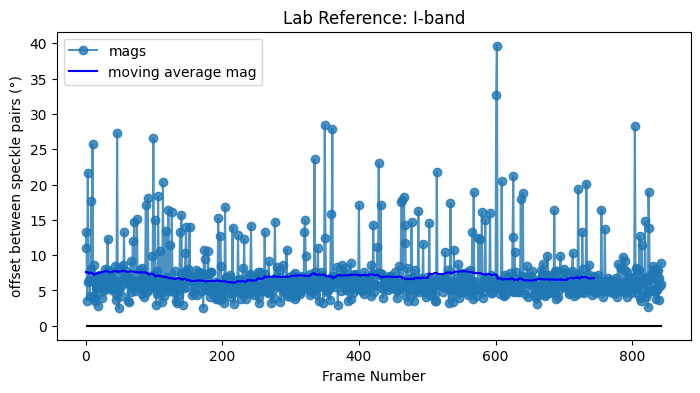

In [ ]:
avg1 = moving_average((mags),n=100)
avg2 = moving_average((angs),n=100)

plt.figure(figsize=(18,4))
plt.subplot(1,2,1)
plt.plot((mags),'-o',label='mags',alpha=0.8)
#plt.plot((angs),'-o',label='angs',alpha=0.8)
plt.plot(avg1,'-',label='moving average mag',color='blue')
#plt.plot(avg2,'-',label='moving average ang',color='orange')
plt.hlines(0,0,len(mags),'black')
plt.xlabel('Frame Number')
plt.ylabel('offset between speckle pairs (°)')
plt.title('Lab Reference: I-band')
plt.legend()